# Week 5 - Part D3: the normalized choropleth

`district_health.csv` + `districts.geojson`, the six steps from slide 50: project, join (and count failures), normalize, classify, colour, caption. Then the count goes back on beside the map as a sorted bar chart (slide 47, row 3).

All data is synthetic course data for CDB601220 (Week 5).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import geolib as gl
from vizlib import PALETTE, save_fig, style_defaults

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
SUB = ROOT / "submission"
for p in (CHARTS, SUB):
    p.mkdir(exist_ok=True)
style_defaults()
BLUE, ORANGE = PALETTE["series"][0], PALETTE["highlight"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
EXTRACTED = "24 Oct 2026"          # the day I pulled the files from the course repository

## Steps 1-3 · Project, join, normalize

In [2]:
feats = gl.read_geojson(DATA / "districts.geojson")
dh = pd.read_csv(DATA / "district_health.csv")
LAT_TS = gl._collection_lat_ts(feats)
print(f"projection: Lambert cylindrical equal-area (geolib.equal_area_xy), one reference latitude for every layer: {LAT_TS:.2f}°N")

geo = {f["code"] for f in feats}
failed_rows = sorted(set(dh.code) - geo)
failed_polys = sorted(geo - set(dh.code))
print(f"join on code: {len(set(dh.code) & geo)} matched | table rows with no polygon: {len(failed_rows)} | polygons with no row: {len(failed_polys)}")
assert len(dh) == 24 and not failed_rows and not failed_polys and dh.code.is_unique

dh["rate"] = dh.cases / dh.population * 1e5
pooled = dh.cases.sum() / dh.population.sum() * 1e5
top_rate = dh.nlargest(3, "rate").code.tolist()
top_count = dh.nlargest(3, "cases").code.tolist()
r_cp = dh.cases.corr(dh.population)
print(f"national pooled rate {pooled:.1f} per 100,000 from {dh.cases.sum():,} cases in {dh.population.sum():,} people")
print(f"top 3 by rate {top_rate} | by count {top_count} | overlap {len(set(top_rate) & set(top_count))} | r(cases, population) = {r_cp:+.3f}")
assert round(pooled, 1) == 52.8 and dh.cases.sum() == 30_564
assert top_rate == ["D19", "D20", "D21"] and top_count == ["D17", "D13", "D09"] and round(r_cp, 3) == 0.986

# suppression rule, set before looking at the map
MIN_CASES, MIN_POP = 20, 50_000
suppress = dh[(dh.cases < MIN_CASES) | (dh.population < MIN_POP)]
print(f"suppression rule: no rate published from < {MIN_CASES} cases or < {MIN_POP:,} residents -> {len(suppress)} districts suppressed "
      f"(smallest: {dh.cases.min()} cases, {dh.population.min():,} residents)")

projection: Lambert cylindrical equal-area (geolib.equal_area_xy), one reference latitude for every layer: 30.50°N
join on code: 24 matched | table rows with no polygon: 0 | polygons with no row: 0
national pooled rate 52.8 per 100,000 from 30,564 cases in 57,857,000 people
top 3 by rate ['D19', 'D20', 'D21'] | by count ['D17', 'D13', 'D09'] | overlap 0 | r(cases, population) = +0.986
suppression rule: no rate published from < 20 cases or < 50,000 residents -> 0 districts suppressed (smallest: 186 cases, 468,000 residents)


## Step 4 · Classify

In [3]:
scores = {}
for sch in ["equal", "quantile", "natural"]:
    e = gl.breaks(dh.rate, sch, 5)
    scores[sch] = gl.gvf(dh.rate, e)
    print(f"{sch:>9s}: breaks {[round(float(x), 1) for x in e]}  GVF {scores[sch]:.3f}  counts {np.bincount(gl.class_of(dh.rate, e), minlength=5).tolist()}")
EDGES = gl.breaks(dh.rate, "natural", 5)

    equal: breaks [30.4, 39.6, 48.9, 58.1, 67.3, 76.5]  GVF 0.969  counts [3, 6, 6, 6, 3]
 quantile: breaks [30.4, 43.8, 49.8, 54.1, 63.0, 76.5]  GVF 0.908  counts [5, 5, 4, 5, 5]
  natural: breaks [30.4, 33.8, 47.5, 54.4, 64.8, 76.5]  GVF 0.969  counts [3, 6, 6, 6, 3]


**Scheme: natural breaks (Jenks), 5 classes.** It has the highest goodness of variance fit (0.969; equal interval ties it here, quantile is 0.908). The rates have a real gap between 33.8 and 42.2 per 100,000 (the biggest jump in the sorted list), and Jenks puts a class edge exactly there instead of splitting a cluster. Quantile would force 4-5 districts into each class whatever the values, which is case 5's trap.

## Steps 5-6 · Colour and caption, then the count beside the map

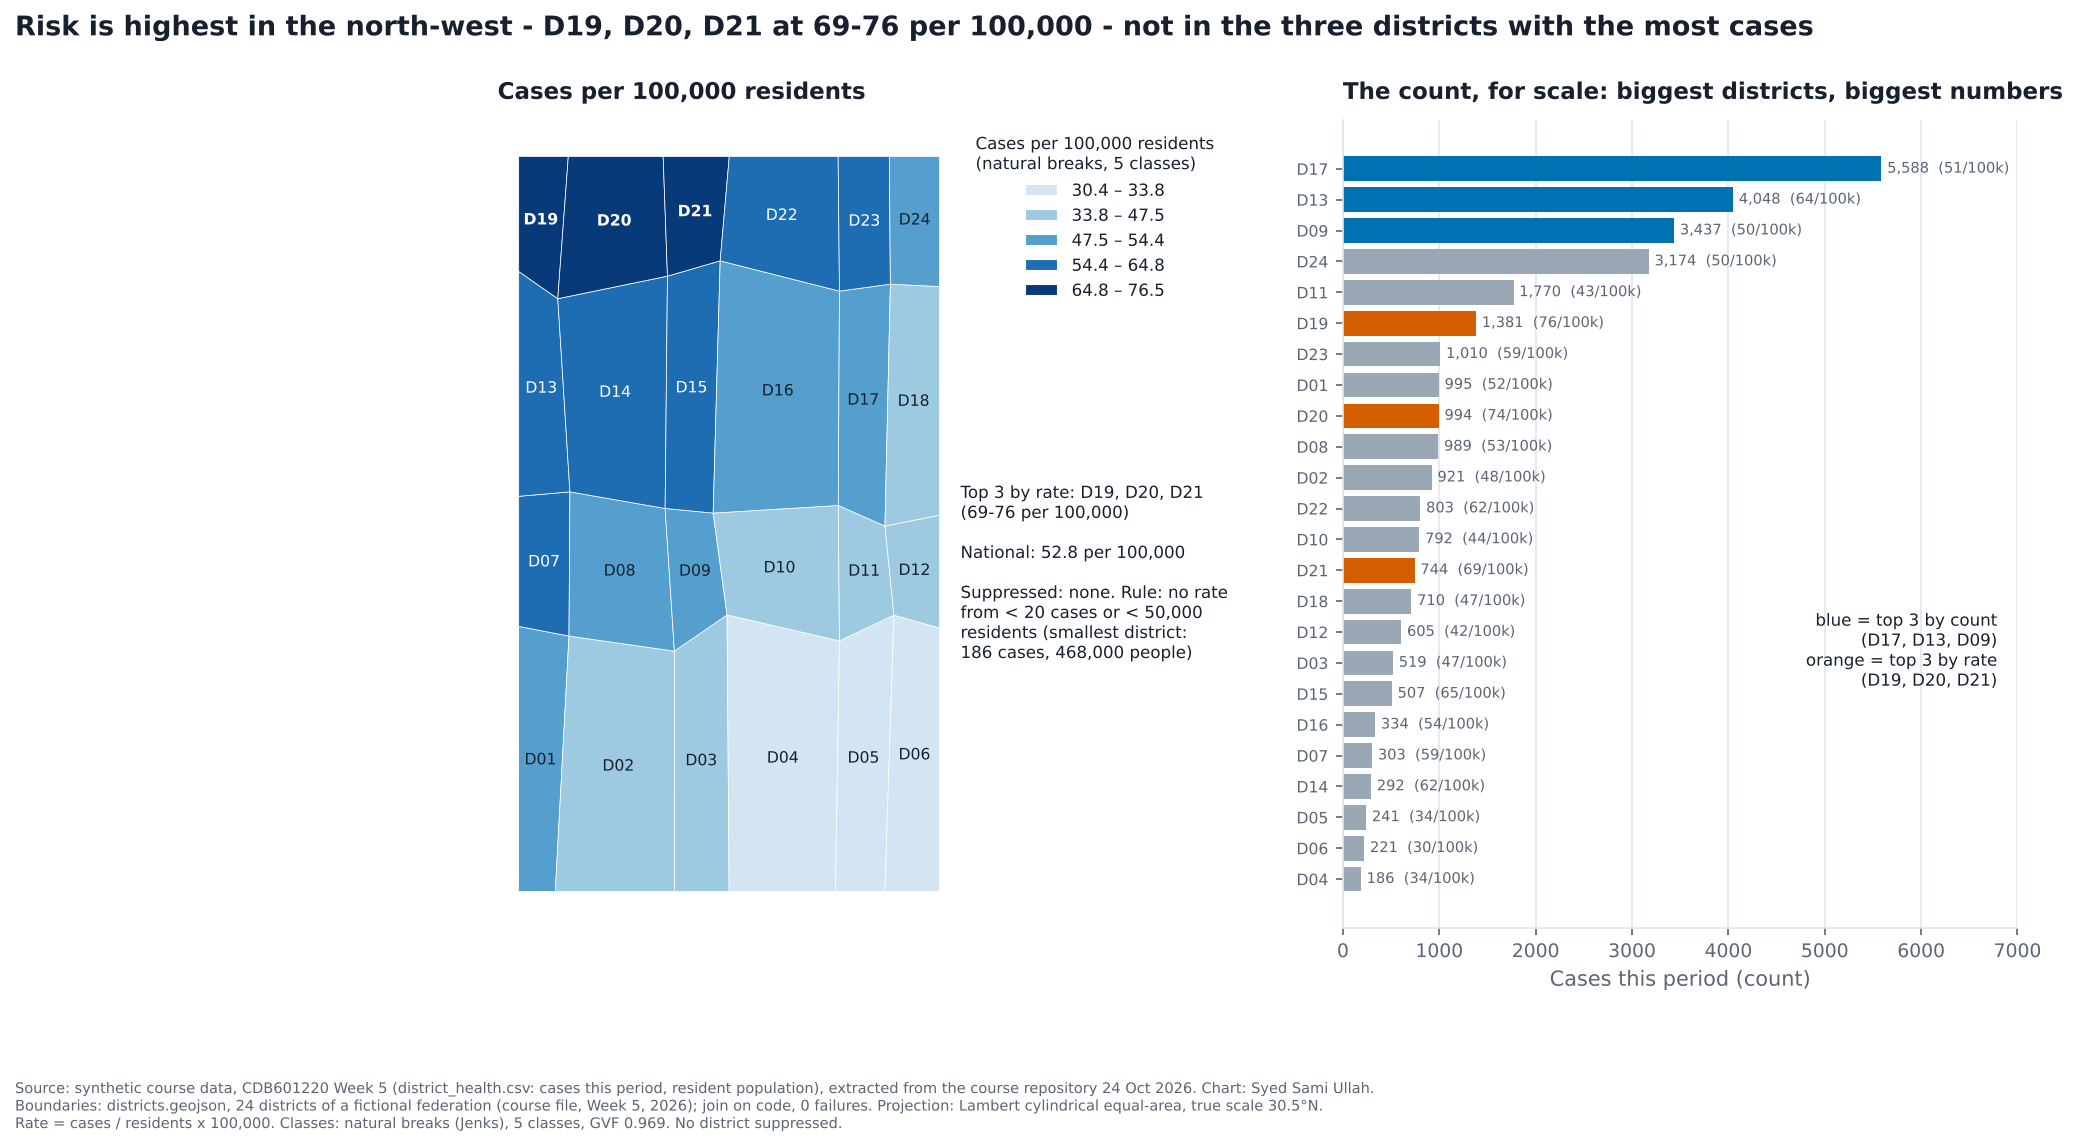

In [4]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.35, 1]})
gl.choropleth(ax, feats, dict(zip(dh.code, dh.rate)), "natural", 5, cmap=PALETTE["sequential"], fmt="{:.1f}",
              legend_title="Cases per 100,000 residents\n(natural breaks, 5 classes)")
cls = dict(zip(dh.code, gl.class_of(dh.rate, EDGES)))
for f in feats:
    x, y = gl.equal_area_xy(*gl.representative_point(f["ring"]), lat_ts=LAT_TS)
    ax.text(x, y, f["code"], ha="center", va="center", fontsize=7.5, color="white" if cls[f["code"]] >= 3 else INK,
            fontweight="bold" if f["code"] in top_rate else "normal")
ax.text(1.0, 0.55, f"Top 3 by rate: {', '.join(top_rate)}\n(69-76 per 100,000)\n\nNational: {pooled:.1f} per 100,000\n\n"
        f"Suppressed: none. Rule: no rate\nfrom < {MIN_CASES} cases or < {MIN_POP:,}\nresidents (smallest district:\n"
        f"{dh.cases.min()} cases, {dh.population.min():,} people)",
        transform=ax.transAxes, fontsize=8, va="top", color=INK)
ax.set_title("Cases per 100,000 residents", fontsize=11)

srt = dh.sort_values("cases")
cols = [ORANGE if c in top_rate else (BLUE if c in top_count else GREY) for c in srt.code]
ax2.barh(srt.code, srt.cases, color=cols)
for y, (_, rr) in enumerate(srt.iterrows()):
    ax2.text(rr.cases + 60, y, f"{rr.cases:,}  ({rr.rate:.0f}/100k)", va="center", fontsize=7, color=SOFT)
ax2.set_xlim(0, 7000)
ax2.tick_params(axis="y", labelsize=7.5)
ax2.set_xlabel("Cases this period (count)")
ax2.set_title("The count, for scale: biggest districts, biggest numbers", fontsize=11)
ax2.grid(axis="y", visible=False)
ax2.text(0.97, 0.30, "blue = top 3 by count\n(D17, D13, D09)\norange = top 3 by rate\n(D19, D20, D21)",
         transform=ax2.transAxes, ha="right", fontsize=8, color=INK)
fig.suptitle("Risk is highest in the north-west - D19, D20, D21 at 69-76 per 100,000 - not in the three districts with the most cases",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
note = (f"Source: synthetic course data, CDB601220 Week 5 (district_health.csv: cases this period, resident population), "
        f"extracted from the course repository {EXTRACTED}. Chart: Syed Sami Ullah.\n"
        f"Boundaries: districts.geojson, 24 districts of a fictional federation (course file, Week 5, 2026); join on code, 0 failures. "
        f"Projection: Lambert cylindrical equal-area, true scale {LAT_TS:.1f}°N.\n"
        f"Rate = cases / residents x 100,000. Classes: natural breaks (Jenks), 5 classes, GVF {scores['natural']:.3f}. No district suppressed.")
save_fig(fig, CHARTS / "partD_choropleth.png", note=note)
save_fig(fig, SUB / "partD_choropleth.png")
show()

**What this chart shows.** Per resident, the outbreak is worst along the north-west edge: D19, D20 and D21 run at 69-76 per 100,000 against a national 52.8. The bars on the right put the count back. D17, D13 and D09 have the most cases because they have the most people (r = +0.986), but two of them (D17 at 51, D09 at 50) are actually slightly below the national rate. None of the top three by count is in the top three by rate.